# 01. Data Audit: Snapshot Serengeti Labels (Season 1)

**Purpose of this notebook**

Before cleaning or modelling, we look at the raw labels file to understand what it contains and how we can work around the data available.

**NOTE:**

This notebook only **explores**. The actual cleaning is done by the pipeline scripts in `src/camtrap/data/`, so that it is reproducible.

### Step 1: Load the libraries


In [11]:
# Import the libraries we need
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Make results repeatable
SEED = 42

### Step 2: Open the labels file

The file was downloaded by `src/camtrap/data/download.py` into `data/raw/`.

This notebook lives in the `notebooks/` folder of my work and can be accessed there.

In [13]:
# Open the Season 1 labels file
labels_path = Path("../data/raw/SnapshotSerengetiS01.json")

with open(labels_path) as f:
    labels = json.load(f)        

# The file is a dictionary; its keys are the "tables" stored inside it
print(labels.keys())

dict_keys(['info', 'categories', 'images', 'annotations'])


### Step 3: Turn the file into tables

The file follows a standard camera-trap format (called *COCO Camera Traps*) with three main parts:

| Part | One row per... | Example |
|------|----------------|---------|
| `images` | photo | file name, camera (location), time, sequence |
| `annotations` | label given to a photo | photo id + category id |
| `categories` | label name | 1 = zebra, 0 = empty, ... |

We convert each part into a pandas DataFrame to make it easier to work on and with.

In [14]:
# Turn each part into a pandas table
images = pd.DataFrame(labels["images"])             
annotations = pd.DataFrame(labels["annotations"])    
categories = pd.DataFrame(labels["categories"])     

print("Photos:     ", images.shape)
print("Labels:     ", annotations.shape)
print("Categories: ", categories.shape)

Photos:      (411414, 10)
Labels:      (412858, 15)
Categories:  (61, 2)


### Step 4: Data Check Protocol

We look at the first rows of each table to see which columns exist and what the values look like as a way to confirm that our data is well loaded.

In [15]:
# Load/check photos table
images.head()

,id,file_name,frame_num,seq_id,width,height,corrupt,location,seq_num_frames,datetime
0,S1/O10/O10_R2/S1_O10_R2_PICT5802,S1/O10/O10_R2/S1_O10_R2_PICT5802.JPG,3,SER_S1#O10#2#1934,2048,1536,False,O10,3,2010-10-09 13:02:40
1,S1/U12/U12_R1/S1_U12_R1_PICT0818,S1/U12/U12_R1/S1_U12_R1_PICT0818.JPG,1,SER_S1#U12#1#274,2048,1536,False,U12,3,2010-09-23 10:23:52
2,S1/E06/E06_R4/S1_E06_R4_PICT0505,S1/E06/E06_R4/S1_E06_R4_PICT0505.JPG,3,SER_S1#E06#4#169,2048,1536,False,E06,3,2010-08-23 11:39:36
3,S1/O10/O10_R1/S1_O10_R1_PICT0265,S1/O10/O10_R1/S1_O10_R1_PICT0265.JPG,3,SER_S1#O10#1#89,2048,1536,False,O10,3,2010-09-05 11:13:12
4,S1/K09/K09_R1/S1_K09_R1_PICT5751,S1/K09/K09_R1/S1_K09_R1_PICT5751.JPG,2,SER_S1#K09#1#1219,2048,1536,False,K09,3,2010-10-13 12:59:08


In [16]:
# Load/Check labels table
annotations.head()

,sequence_level_annotation,id,category_id,seq_id,season,datetime,subject_id,count,standing,resting,moving,interacting,young_present,image_id,location
0,True,1ab1a30c-955a-11e9-ad1e-000d3a198845,1,SER_S1#B04#1#1,S1,2010-07-18 16:26:14,ASG0002kjh,1,0.62,0.06,0.0,0.50,0.0,S1/B04/B04_R1/S1_B04_R1_PICT0001,B04
1,True,1ab1a30d-955a-11e9-a37d-000d3a198845,1,SER_S1#B04#1#2,S1,2010-07-18 16:26:30,ASG0002kji,2,0.10,0.62,0.0,0.33,0.0,S1/B04/B04_R1/S1_B04_R1_PICT0002,B04
2,True,1ab1a30e-955a-11e9-aeae-000d3a198845,0,SER_S1#B04#1#3,S1,2010-07-20 06:14:06,ASG0002kjj,NaN,NaN,NaN,NaN,NaN,NaN,S1/B04/B04_R1/S1_B04_R1_PICT0003,B04
3,True,1ab1a30f-955a-11e9-980a-000d3a198845,0,SER_S1#B04#1#4,S1,2010-07-22 08:56:06,ASG0002kjk,NaN,NaN,NaN,NaN,NaN,NaN,S1/B04/B04_R1/S1_B04_R1_PICT0004,B04
4,True,1ab1a310-955a-11e9-99ae-000d3a198845,0,SER_S1#B04#1#5,S1,2010-07-24 01:16:28,ASG0002kjl,NaN,NaN,NaN,NaN,NaN,NaN,S1/B04/B04_R1/S1_B04_R1_PICT0005,B04


In [17]:
# Check all label names
categories

,id,name
0,0,empty
1,1,human
2,2,gazellegrants
3,3,reedbuck
4,4,dikdik
...,...,...
56,56,hyenabrown
57,57,wilddog
58,58,kudu
59,59,pangolin


### Findings from the first look

- The photos table records **where and when** each photo was taken; the labels table records **what is in it**, plus behaviour details (count, standing, resting, ...)

Steps 5 to 11 examine each part in detail.

### Step 5: How the tables fit together

Before combining the tables, we confirm they can be trusted.

- **5a.** Are the IDs unique, and does every label match a photo?
- **5b.** Do the camera and time agree between the two tables?
- **5c.** How are the photos grouped? A camera takes a **burst** of photos each time it is triggered, and its memory card is collected in **rolls**.

In [18]:
# 5a. Are the IDs unique?
print("Duplicate photo ids:", images["id"].duplicated().sum())
print("Duplicate label ids:", annotations["id"].duplicated().sum())

# Does every label point to a photo that exists, and does every photo have a label?
print("Labels with no matching photo:", (~annotations["image_id"].isin(images["id"])).sum())
print("Photos with no label:         ", (~images["id"].isin(annotations["image_id"])).sum())

Duplicate photo ids: 0
Duplicate label ids: 0
Labels with no matching photo: 0
Photos with no label:          0


In [19]:
# 5b. Do the camera and time agree between the two tables?
joined = annotations.merge(images[["id", "location", "datetime"]],
                           left_on="image_id", right_on="id", suffixes=("", "_photo"))

print("Rows compared:          ", f"{len(joined):,}")
print("Camera does not match:  ", (joined["location"] != joined["location_photo"]).sum())
print("Time does not match:    ", (joined["datetime"] != joined["datetime_photo"]).sum())

Rows compared:           412,858
Camera does not match:   0
Time does not match:     0


In [20]:
# 5c. How photos group into bursts, rolls and cameras
# The file name holds the season, camera and roll, e.g. S1/B04/B04_R1/S1_B04_R1_PICT0001.JPG
images["roll"] = images["file_name"].str.split("/").str[2]      # e.g. B04_R1

print("Cameras:", images["location"].nunique())
print("Rolls (memory-card collections):", images["roll"].nunique())
print("Bursts:", f"{images['seq_id'].nunique():,}")
print("Photos:", f"{len(images):,}")

print("\nPhotos per burst:")
print(images.groupby("seq_id").size().value_counts().sort_index().to_string())

Cameras: 168
Rolls (memory-card collections): 284
Bursts: 148,226
Photos: 411,414

Photos per burst:
1     16459
2       349
3    131416
4         1
5         1


#### What we found

- The IDs are unique, every label matches a photo, and every photo has at least one label.
- Camera and time agree in all 412,858 rows, so the two tables can be joined safely.
- The data is nested: **168 cameras → 284 rolls → 148,226 bursts → 411,414 photos**.
- Most bursts have 3 photos (131,416); 16,459 have a single photo.
- **Consequence:**
The photos from one burst are near-copies of the same moment, and photos from one camera share the same background. Both must stay together when the data is split in the steps to come. 

### Step 6: What a label really means

- **6a.** Is a label given to a single photo or to the whole burst?
- **6b.** How many bursts carry more than one label?
- **6c.** Which labels are not a single species, or split one species into parts?

In [21]:
# 6a. Add the label name to every row (category_id 0 -> "empty", 5 -> "zebra", ...)
names = dict(zip(categories["id"], categories["name"]))
annotations["label"] = annotations["category_id"].map(names)

# Every label is marked as belonging to the whole burst?
print(annotations["sequence_level_annotation"].value_counts().to_string())

# Do all photos in a burst carry the same set of labels?
labels_per_photo = annotations.groupby(["seq_id", "image_id"])["label"].apply(lambda x: tuple(sorted(x)))
different_sets = labels_per_photo.groupby("seq_id").nunique()
print("\nBursts whose photos carry different labels:", (different_sets > 1).sum())

sequence_level_annotation
True    412858

Bursts whose photos carry different labels: 0


In [22]:
# 6b. One row per burst, with the set of labels it carries
bursts = (
    annotations.groupby("seq_id")
               .agg(location=("location", "first"),
                    labels=("label", lambda x: tuple(sorted(set(x)))))
               .reset_index()
)
bursts["n_labels"] = bursts["labels"].apply(len)

print("Bursts by number of different labels:")
print(bursts["n_labels"].value_counts().sort_index().to_string())

print("\nMost common combinations in multi-label bursts:")
print(bursts.loc[bursts["n_labels"] > 1, "labels"].value_counts().head(10).to_string())

Bursts by number of different labels:
n_labels
1    147730
2       490
3         6

Most common combinations in multi-label bursts:
labels
(gazellethomsons, otherbird)        80
(gazellegrants, gazellethomsons)    70
(gazellethomsons, zebra)            41
(gazellethomsons, hartebeest)       26
(gazellethomsons, warthog)          25
(lionfemale, lionmale)              21
(otherbird, warthog)                21
(gazellethomsons, koribustard)      18
(gazellethomsons, human)            15
(wildebeest, zebra)                 14


In [23]:
# 6c. Labels that are not a single species, or that split one species into parts
special = ["empty", "human", "otherbird", "reptiles", "rodents", "insectspider", "fire",
           "lionfemale", "lionmale", "lioncub"]

burst_counts = annotations.groupby("label")["seq_id"].nunique()     # bursts per label
print(burst_counts.reindex(special).fillna(0).astype(int).to_string())

label
empty           122537
human             1957
otherbird          871
reptiles           119
rodents             43
insectspider         0
fire                 0
lionfemale         509
lionmale           223
lioncub              0


#### What we found

- All labels are marked as burst-level, and every photo in a burst carries the same labels. 

A label therefore describes the burst, not each photo: for example, if an animal walks out of view, the last photo may be empty but still carry the animal's label. This is a source of **label noise**.

- 496 bursts carry two or three labels. Most are a main species with a bird or another grazer (Thomson's gazelle + other bird: 80 bursts). 
 21 are female + male lion, which become one label once lions are merged.

- Some labels group several species: `otherbird` (871 bursts), `reptiles` (119), `rodents` (43). `insectspider` and `fire` never appear in Season 1.


- Lions are split by sex and age: `lionfemale` (509 bursts), `lionmale` (223), `lioncub` (none). For species classification they become one class, `lion`.

### Step 7: Class balance

Counting photos overstates how much data we have, because the photos of a burst show the same moment. We therefore count **bursts**.

- **7a.** Photos and bursts per species (lions merged)
- **7b.** Bursts per species, on a log scale
- **7c.** How many species have enough bursts to learn from?

In [26]:
# 7a. Merge the three lion labels into one species
annotations["species"] = annotations["label"].replace(
    {"lionfemale": "lion", "lionmale": "lion", "lioncub": "lion"})

# Count each species twice: by photos and by bursts
by_photos = annotations.groupby("species")["image_id"].nunique()
by_bursts = annotations.groupby("species")["seq_id"].nunique()

counts = pd.DataFrame({"photos": by_photos, "bursts": by_bursts}).sort_values("bursts", ascending=False)
counts["share_of_bursts"] = (counts["bursts"] / bursts["seq_id"].nunique()).round(4)
print(counts.head(15).to_string())

                 photos  bursts  share_of_bursts
species                                         
empty            338837  122537           0.8267
gazellethomsons   29705   10467           0.0706
human              4802    1957           0.0132
zebra              5592    1893           0.0128
gazellegrants      4967    1709           0.0115
guineafowl         3217    1097           0.0074
hyenaspotted       2752     968           0.0065
warthog            2685     961           0.0065
otherbird          2322     871           0.0059
hartebeest         2139     719           0.0049
lion               2121     711           0.0048
giraffe            1923     696           0.0047
elephant           1687     604           0.0041
buffalo            1455     493           0.0033
reedbuck            946     328           0.0022


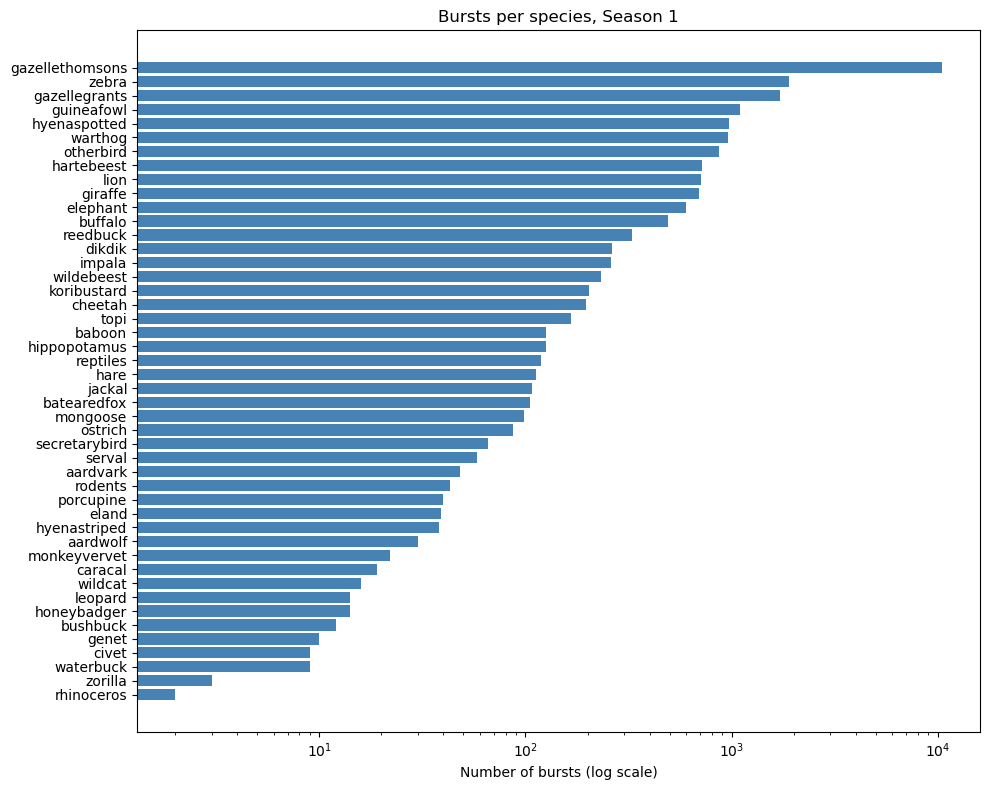

In [27]:
# 7b. Bursts per species (empty and human left out), on a log scale
animals = counts.drop(index=["empty", "human"])

plt.figure(figsize=(10, 8))
plt.barh(animals.index[::-1], animals["bursts"][::-1], color="steelblue")
plt.xscale("log")                     # log scale: otherwise the rare species are invisible
plt.xlabel("Number of bursts (log scale)")
plt.title("Bursts per species, Season 1")
plt.tight_layout()
plt.show()

In [28]:
# 7c. How many species have enough examples to learn from?
for minimum in [50, 100, 200, 500, 1000]:
    n = (animals["bursts"] >= minimum).sum()
    print(f"Species with at least {minimum:>4} bursts: {n}")

Species with at least   50 bursts: 29
Species with at least  100 bursts: 25
Species with at least  200 bursts: 17
Species with at least  500 bursts: 11
Species with at least 1000 bursts: 4


#### What we found

- **82.7%** of bursts are empty. A model that always answered "empty" would be right 82.7% of the time and still be useless, so accuracy cannot be our main measure when analyzing the metrics. 

- Among animals, Thomson's gazelle dominates with 10,467 bursts, more than the next five species combined. Rhinoceros and zorilla appear in only 2–3 bursts.
- Counting photos instead of bursts inflates every class about threefold.
- Species with at least 100 / 200 / 500 bursts: **25 / 17 / 11** (including group labels such as `otherbird`).

### Step 8: Cameras

Our main question is whether the model works on cameras it has never seen, so we need to know how different the cameras are.

- **8a.** Photos and share of empty labels per camera
- **8b.** How much of the data comes from the busiest cameras?
- **8c.** At how many cameras does each species appear?

         photos  empty_rate
count    168.00      168.00
mean    2448.89        0.65
std     2411.76        0.28
min       11.00        0.15
25%      534.50        0.38
50%     1334.50        0.71
75%     3798.75        0.94
max    11620.00        1.00


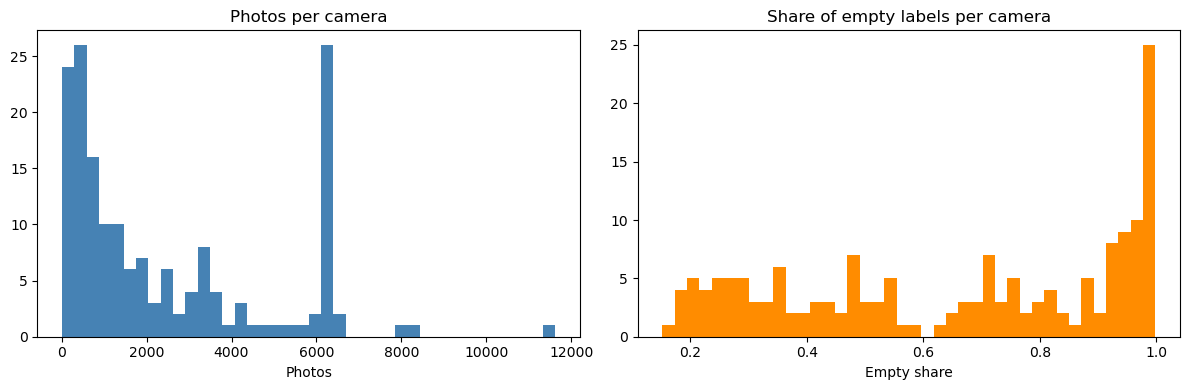

In [29]:
# 8a. Photos and empty rate per camera
annotations["is_empty"] = annotations["label"] == "empty"

per_camera = pd.DataFrame({
    "photos": images.groupby("location").size(),
    "empty_rate": annotations.groupby("location")["is_empty"].mean(),
})
print(per_camera.describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(per_camera["photos"], bins=40, color="steelblue")
axes[0].set_title("Photos per camera")
axes[0].set_xlabel("Photos")
axes[1].hist(per_camera["empty_rate"], bins=40, color="darkorange")
axes[1].set_title("Share of empty labels per camera")
axes[1].set_xlabel("Empty share")
plt.tight_layout()
plt.show()

In [30]:
# 8b. The cameras with the most photos, and how empty they are
print(per_camera.sort_values("photos", ascending=False).head(10).round(3).to_string())

# What share of all photos comes from the busiest 10% of cameras?
top_10pct = per_camera["photos"].sort_values(ascending=False).head(len(per_camera) // 10)
print(f"\nShare of all photos from the busiest 10% of cameras: {top_10pct.sum() / len(images):.1%}")

          photos  empty_rate
location                    
C03        11620       0.984
O10         8356       0.947
F08         7850       0.804
L10         6582       0.957
N12         6445       0.993
I03         6380       0.960
F02         6357       0.925
I09         6333       0.986
K12         6291       0.997
H11         6285       0.984

Share of all photos from the busiest 10% of cameras: 26.8%


In [31]:
# 8c. At how many cameras does each species appear?
cameras_per_species = annotations.groupby("species")["location"].nunique()

# Cameras where the species has at least 5 bursts (seen more than by chance)
bursts_per_cam = annotations.groupby(["species", "location"])["seq_id"].nunique()
regular_cameras = (bursts_per_cam >= 5).groupby("species").sum()

spread = pd.DataFrame({
    "bursts": animals["bursts"],
    "cameras": cameras_per_species,
    "cameras_with_5plus": regular_cameras,
}).loc[animals.index]
print(spread.to_string())

                  bursts  cameras  cameras_with_5plus
species                                              
gazellethomsons  10467.0      120                  89
zebra             1893.0       88                  55
gazellegrants     1709.0      109                  65
guineafowl        1097.0       65                  36
hyenaspotted       968.0      115                  39
warthog            961.0       93                  44
otherbird          871.0      108                  33
hartebeest         719.0       71                  25
lion               711.0       70                  30
giraffe            696.0       90                  46
elephant           604.0       71                  33
buffalo            493.0       42                  21
reedbuck           328.0       72                  10
dikdik             262.0       65                  18
impala             261.0       38                  14
wildebeest         233.0       45                   4
koribustard        203.0    

#### What we found

- Cameras are very unequal: from 11 to 11,620 photos. 

- The empty share ranges from 15% to 100%. The busiest cameras are mostly the emptiest (camera C03: 11,620 photos, 98% empty), which points to false triggers such as moving grass.

- Species are not spread evenly. Wildebeest has 233 bursts but appears regularly (5+ bursts) at only **4 cameras**; cheetah has 197 bursts at 5 cameras.

- **Consequence:**  A species concentrated at a few cameras may end up entirely in training or entirely in testing. Choosing classes needs enough bursts **and** enough cameras. Without a limit per camera, a few busy cameras would also dominate the training data.

### Step 9: Time of day

- **9a.** Can every date be read, and are all dates inside Season 1?
- **9b.** What share of photos is taken at night, overall and per species?
- **9c.** At what hours is each species photographed?

Night is taken as **19:00–05:59**. The Serengeti lies close to the equator, so sunrise (about 06:30) and sunset (about 18:45) barely change through the year. 

Night photos are darker and look different from day photos, so they are expected to be harder to classify.

In [32]:
# 9a. Turn the text dates into real dates; dates that cannot be read become NaT
images["datetime"] = pd.to_datetime(images["datetime"], errors="coerce")
print("Unreadable dates:", images["datetime"].isna().sum())

# Season 1 ran from mid-July to early November 2010
bad_date = (images["datetime"] < "2010-07-01") | (images["datetime"] > "2010-11-30")
print("Photos dated outside the season:", bad_date.sum())
print(images.loc[bad_date, ["location", "datetime"]].sort_values("location").to_string())

Unreadable dates: 0
Photos dated outside the season: 6
       location            datetime
18771       I09 2011-02-01 12:27:54
301986      I09 2011-02-01 12:27:54
319455      I09 2011-02-01 12:27:54
208065      K11 2010-01-05 19:02:54
233576      K11 2010-01-05 19:02:54
257097      K11 2010-01-05 19:02:54


In [33]:
# 9b. Day or night? The Serengeti is near the equator: sunrise ~06:30, sunset ~18:45 all year
images["hour"] = images["datetime"].dt.hour
images["is_night"] = (images["hour"] >= 19) | (images["hour"] < 6)

valid = images[~bad_date]
print(f"Share of photos taken at night: {valid['is_night'].mean():.1%}")

# Night share for each species (one row per labelled photo)
labelled = annotations.merge(valid[["id", "hour", "is_night"]], left_on="image_id", right_on="id")
night_share = labelled.groupby("species")["is_night"].mean()
print("\nNight share, main species:")
print(night_share.reindex(animals.index[:15]).round(2).to_string())

Share of photos taken at night: 18.8%

Night share, main species:
species
gazellethomsons    0.11
zebra              0.27
gazellegrants      0.10
guineafowl         0.00
hyenaspotted       0.51
warthog            0.01
otherbird          0.06
hartebeest         0.07
lion               0.14
giraffe            0.17
elephant           0.28
buffalo            0.24
reedbuck           0.64
dikdik             0.70
impala             0.24


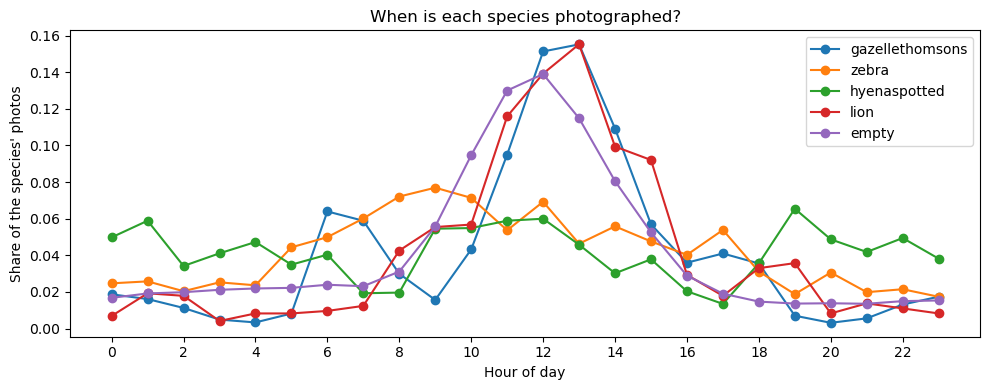

In [34]:
# 9c. Activity through the day for a few species
plt.figure(figsize=(10, 4))
for sp in ["gazellethomsons", "zebra", "hyenaspotted", "lion", "empty"]:
    hourly = labelled.loc[labelled["species"] == sp, "hour"].value_counts(normalize=True).sort_index()
    plt.plot(hourly.index, hourly.values, marker="o", label=sp)
plt.xlabel("Hour of day")
plt.ylabel("Share of the species' photos")
plt.title("When is each species photographed?")
plt.xticks(range(0, 24, 2))
plt.legend()
plt.tight_layout()
plt.show()

#### What we found

- All dates can be read. **6 photos** are dated outside Season 1: 3 on camera K11 (January 2010) and 3 on camera I09 (February 2011), most likely wrong camera clocks.

- **18.8%** of photos are taken at night.

- Species differ strongly: guineafowl and warthog are almost never photographed at night (1% or less), while spotted hyena (51%), reedbuck (64%) and dik-dik (70%) are mostly seen at night.

- **Consequence:** These results will be reported separately for day and night, because night performance matters most for the nocturnal species.

### Step 10: Missing data

Missing data here comes in two forms: **blank cells**, and **photos that do not exist**. For each, we ask whether it is missing completely at random (**MCAR**), at random given something we can observe (**MAR**), or because of the missing information itself (**MNAR**).

- **10a.** Which columns have blank cells?
- **10b.** Are those blanks linked to the label?
- **10c.** Photos that do not exist: withheld photos of people, and bursts with missing frames
- **10d.** Camera downtime: long periods with no photos at all
- **10e.** What did the camera see just before a long gap?

In [35]:
# 10a. Columns with blank cells, in each table
for name, table in [("Photos", images), ("Labels", annotations)]:
    blank_share = table.isna().mean()
    print(f"{name} table:")
    if (blank_share > 0).any():
        print(blank_share[blank_share > 0].round(4).to_string())
    else:
        print("  no blank cells")
    print()

Photos table:
  no blank cells

Labels table:
count            0.8207
standing         0.8207
resting          0.8207
moving           0.8207
interacting      0.8207
young_present    0.8207



In [36]:
# 10b. Are the blank behaviour columns linked to the label?
behaviour = ["count", "standing", "resting", "moving", "interacting", "young_present"]
all_blank = annotations[behaviour].isna().all(axis=1)

print("Rows where all six are blank:", f"{all_blank.sum():,}")
print(f"Empty share when blank:   {annotations.loc[all_blank, 'is_empty'].mean():.1%}")
print(f"Empty share when filled:  {annotations.loc[~all_blank, 'is_empty'].mean():.1%}")

Rows where all six are blank: 338,837
Empty share when blank:   100.0%
Empty share when filled:  0.0%


In [37]:
# 10c. Photos that do not exist: withheld photos of people, and missing frames
human_bursts = annotations.loc[annotations["label"] == "human", "seq_id"].unique()
cams_with_people = annotations.loc[annotations["label"] == "human", "location"].nunique()
print("Bursts with people (photos withheld):", f"{len(human_bursts):,}")
print("Cameras that photographed people:   ", cams_with_people, "of", images["location"].nunique())

photos_per_burst = images.groupby("seq_id").size()
recorded = images.groupby("seq_id")["seq_num_frames"].first()
print("\nBursts with fewer photos than recorded:", (photos_per_burst < recorded).sum())

Bursts with people (photos withheld): 1,957
Cameras that photographed people:    168 of 168

Bursts with fewer photos than recorded: 17


In [38]:
# 10d. Camera downtime: days between one burst and the next on the same camera
starts = (
    valid.groupby("seq_id")
         .agg(location=("location", "first"), start=("datetime", "min"))
         .reset_index()
         .sort_values(["location", "start"])
)
starts["gap_days"] = starts.groupby("location")["start"].diff().dt.total_seconds() / 86400

for days in [3, 7, 14]:
    long_gaps = starts[starts["gap_days"] > days]
    print(f"Gaps longer than {days:>2} days: {len(long_gaps):>3}, on {long_gaps['location'].nunique()} cameras")
print(f"Longest gap: {starts['gap_days'].max():.0f} days")

Gaps longer than  3 days: 235, on 90 cameras
Gaps longer than  7 days:  59, on 44 cameras
Gaps longer than 14 days:  22, on 19 cameras
Longest gap: 83 days


In [39]:
# 10e. What did the camera see just before going silent for more than 7 days?
starts["next_gap"] = starts.groupby("location")["gap_days"].shift(-1)
before_gap = starts["next_gap"] > 7

burst_is_empty = annotations.groupby("seq_id")["is_empty"].all()
starts["is_empty"] = starts["seq_id"].map(burst_is_empty)

print("Bursts just before a long gap:", before_gap.sum())
print(f"Not empty, just before a gap: {1 - starts.loc[before_gap, 'is_empty'].mean():.1%}")
print(f"Not empty, all bursts:        {1 - starts['is_empty'].mean():.1%}")

gap_bursts = starts.loc[before_gap, "seq_id"]
print("\nLabels just before a gap (bursts):")
print(annotations.loc[annotations["seq_id"].isin(gap_bursts)].groupby("label")["seq_id"].nunique()
      .sort_values(ascending=False).to_string())

Bursts just before a long gap: 59
Not empty, just before a gap: 47.5%
Not empty, all bursts:        17.3%

Labels just before a gap (bursts):
label
empty              31
human              11
hyenaspotted        3
gazellethomsons     2
warthog             2
elephant            1
cheetah             1
guineafowl          1
giraffe             1
gazellegrants       1
impala              1
jackal              1
lionfemale          1
secretarybird       1
zebra               1


#### What we found

- **Blank cells:** only the six behaviour columns of the labels table, each 82.07% blank. They are blank in every empty burst and filled for every animal. This is **not MCAR**: the blanks are fully explained by the label (**MAR**). In fact these values *cannot exist*, because with no animal there is nothing to count. We drop the columns: an image model does not need them, and they would reveal the label (a blank count alone identifies an empty burst).


- **Withheld photos of people:** 1,957 bursts. These photos were removed **because of what they show**, so they are **MNAR by design**. Every one of the 168 cameras photographed people at least once, which suggests many are researchers servicing the cameras. The model will never see a person.

- **Missing frames:** 17 bursts have fewer photos than recorded; too few to matter.

- **Camera downtime:** 59 gaps longer than a week, on 44 cameras; the longest lasts 83 days. A period without photos is not the same as a period without animals.

- **Before a gap:** 47.5% of the bursts just before a gap are not empty, against 17.3% overall. 11 of the 59 show people, likely a servicing visit (**MAR**: explained by an observed event). The others include hyenas, an elephant and other animals known to damage cameras (possibly **MNAR**). With only 59 gaps, this is suggestive rather than proven.

- Data can rule out MCAR, but it can never prove MAR versus MNAR; for MNAR we rely on knowledge of the field and a bit of reasearch.

### Step 11: Image details

Practical checks before the photos are downloaded.

- **11a.** Image sizes and the `corrupt` flag
- **11b.** How many times each camera's memory card was collected (rolls)

In [41]:
# 11a. Image sizes and the "corrupt" flag
print(images[["width", "height"]].value_counts().to_string())
print("\nCameras with the unusual size:",
      images.loc[images["width"] != 2048, "location"].unique())
print("Photos marked corrupt:", images["corrupt"].sum())

# 11b. Rolls per camera (how often the memory card was collected)
print("\nRolls per camera:")
print(images.groupby("location")["roll"].nunique().value_counts().sort_index().to_string())

width  height
2048   1536      411403
2592   1944          11

Cameras with the unusual size: ['B06' 'B05']
Photos marked corrupt: 0

Rolls per camera:
roll
1    104
2     36
3     13
4      9
5      3
6      3


#### What we found

- 411,403 photos are **2048×1536 pixels**; 11 photos from cameras B05 and B06 are 2592×1944. Every photo will be resized to the same size before training.

- No photo is marked corrupt. This will be checked again when the photos are opened.

- 104 cameras have a single roll; the others have between 2 and 6.

### Step 12: Audit summary and cleaning rules

| # | Finding | Step | Cleaning rule for the pipeline |
|---|---|---|---|
| 1 | Behaviour columns are blank whenever a burst is empty, and would reveal the label | 10 | Drop `count`, `standing`, `resting`, `moving`, `interacting`, `young_present` |
| 2 | 1,957 bursts show people (photos withheld) | 10 | Remove every burst with a `human` label |
| 3 | Labels describe the whole burst | 6 | Work with one label per burst |
| 4 | Lions are split into female, male and cub | 6 | Merge them into `lion` |
| 5 | 496 bursts carry more than one label | 6 | After merging lions, drop bursts that still carry more than one label (0.3%) |
| 6 | Strong class imbalance; some species are seen at only a few cameras | 7, 8 | Keep species with **at least 300 bursts** that appear regularly (5+ bursts) at **10 or more cameras**; put all other animals, including group labels such as `otherbird`, into `other` |
| 7 | 82.7% of bursts are empty | 7 | Keep `empty` as a class, but sample so that it does not dominate the training data |
| 8 | A few busy cameras produce a large share of the photos | 8 | Limit the number of bursts sampled from each camera |
| 9 | Photos from one burst or one camera are near-copies | 5, 8 | Split by camera: no camera appears in more than one of train, validation and test |
| 10 | 6 photos have wrong dates, on 2 cameras | 9 | Keep the photos; leave their dates out of the day/night analysis |
| 11 | Image sizes differ | 11 | Resize every photo to 224×224 pixels |

**Classes that follow from rule 6:** Thomson's gazelle, zebra, Grant's gazelle, guineafowl, spotted hyena, warthog, hartebeest, lion, giraffe, elephant, buffalo and reedbuck (**12 species**), plus `other` and `empty`.